In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

In [ ]:
import kagglehub
import pandas as pd
import os

# 1. Download the dataset (it will save to a hidden Colab cache)
path = kagglehub.dataset_download("amanalisiddiqui/fraud-detection-dataset")

# 2. Find the CSV file inside that hidden folder
files_in_dir = os.listdir(path)
csv_file_name = [f for f in files_in_dir if f.endswith('.csv')][0]
full_file_path = os.path.join(path, csv_file_name)
print("Loading file from:", full_file_path)

# 3. Load the full dataset into Pandas
df = pd.read_csv(full_file_path)

# 4. Verify you have all 6.3+ million rows!
print("Dataset shape:", df.shape)

100%|██████████| 178M/178M [00:01<00:00, 131MB/s]

Extracting files...


Loading file from: /root/.cache/kagglehub/datasets/amanalisiddiqui/fraud-detection-dataset/versions/1/AIML Dataset.csv
Dataset shape: (6362620, 11)


# memory optimization

In [ ]:
import gc

# 1. Downcast integers to smaller types (e.g., int64 -> int32 or int16)
for col in df.select_dtypes(include=['integer']).columns:
    df[col] = pd.to_numeric(df[col], downcast='integer')

# 2. Downcast floats to smaller types (e.g., float64 -> float32)
for col in df.select_dtypes(include=['float']).columns:
    df[col] = pd.to_numeric(df[col], downcast='float')

# 3. Force Python to clear out any leftover unreferenced memory
gc.collect()

print("Memory successfully optimized! Current RAM usage is now minimized.")

Memory successfully optimized! Current RAM usage is now minimized.


In [ ]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
# general information about data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int16  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int8   
 10  isFlaggedFraud  int8   
dtypes: float64(5), int16(1), int8(2), object(3)
memory usage: 412.6+ MB


In [ ]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [ ]:
# no.of fraud and not fraud data
df["isFraud"].value_counts()

,count
isFraud,
0,6354407
1,8213


In [ ]:
# no.of flagged fraud and not fraud data
df["isFlaggedFraud"].value_counts()

,count
isFlaggedFraud,
0,6362604
1,16


In [ ]:
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
df.shape

(6362620, 11)

In [ ]:
# drop the raws with null values
df.dropna(inplace=True)

In [ ]:
#verify those null value rows are gone
print(df.isnull().sum())

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [ ]:
# Check how many exact duplicate rows exist
print(f"Duplicate rows:{df.duplicated().sum()}")


Duplicate rows:0


In [ ]:
#to spot impossible values generate a statsistical summory of the numerical columns
df.describe().astype(int)

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6362620,6362620,6362620,6362620,6362620,6362620,6362620,6362620
mean,243,179861,833883,855113,1100701,1224996,0,0
std,142,603858,2888242,2924048,3399180,3674128,0,0
min,1,0,0,0,0,0,0,0
25%,156,13389,0,0,0,0,0,0
50%,239,74871,14208,0,132705,214661,0,0
75%,335,208721,107315,144258,943036,1111909,0,0
max,743,92445516,59585040,49585040,356015889,356179278,1,1


In [ ]:
# List all unique categories and their frequencies
print(df['type'].value_counts())

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [ ]:
# see the skewness of data
#value_counts()[1] --> calculate the value of 1 --> which is fraud
print(round((df["isFraud"].value_counts()[1]/df.shape[0])*100,5))

0.12908


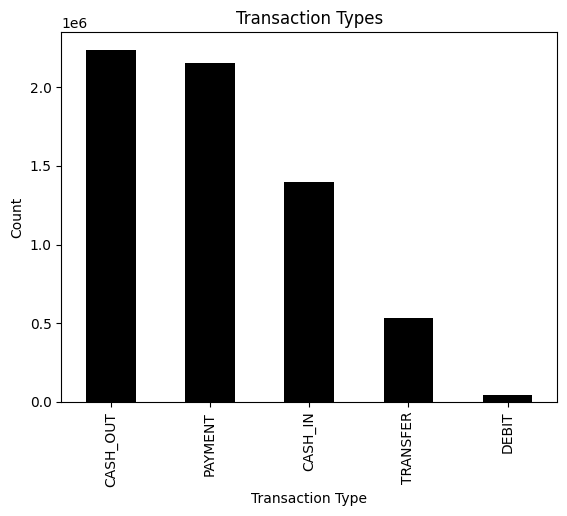

In [ ]:
# visualizing the transaction types
df["type"].value_counts().plot(kind="bar",title="Transaction Types",color="black")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()

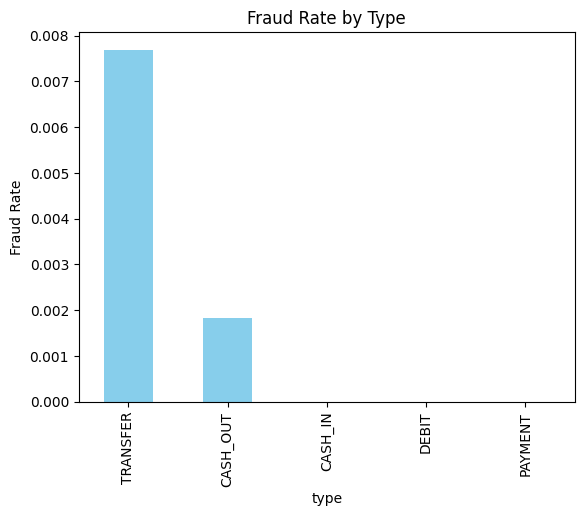

In [ ]:
# find the fraud rate by transaction type
fraud_by_type=df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind="bar",title="Fraud Rate by Type",color="skyblue")
plt.ylabel("Fraud Rate")
plt.show()

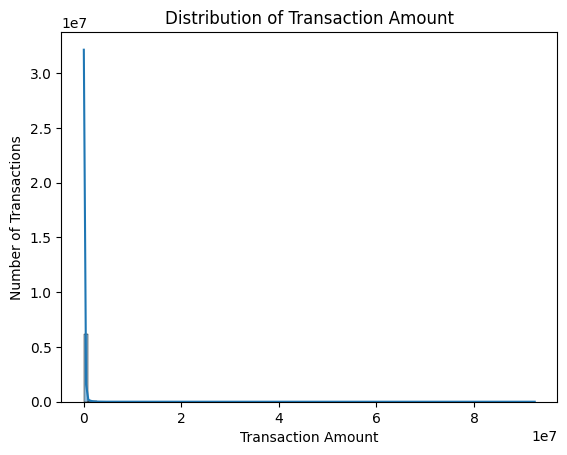

In [ ]:
# first plot the raw amount to see how skewd the data is
sns.histplot(df["amount"], bins=100, kde=True)
plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()

In [ ]:
print(df["amount"].skew())

30.99394948249038


In [ ]:
df["amount_log"]=np.log1p(df["amount"])
# this performs -->amount_log=log(1+amount)

In [ ]:
# check the skewness again
print(df["amount_log"].skew())

-0.5550183204227738


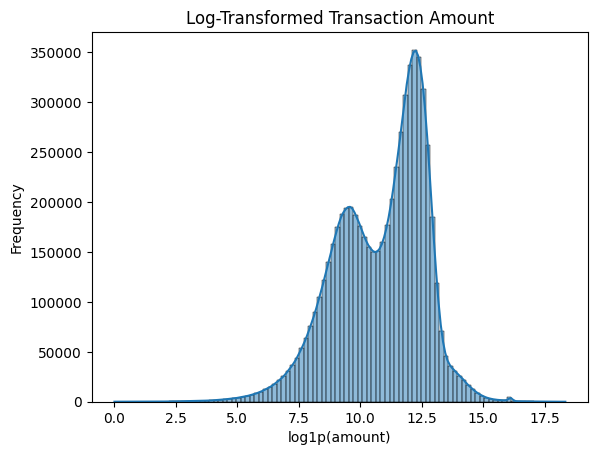

In [ ]:
# plot the transformed distribution
sns.histplot(df["amount_log"], bins=100, kde=True)

plt.title("Log-Transformed Transaction Amount")
plt.xlabel("log1p(amount)")
plt.ylabel("Frequency")

plt.show()

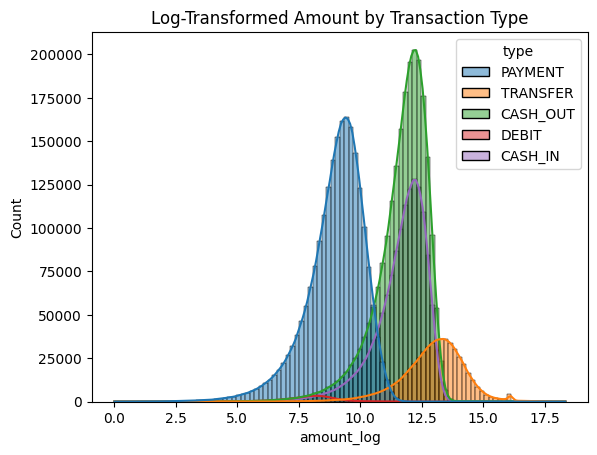

In [ ]:
# Add 'hue' to color the data by transaction type
sns.histplot(data=df, x="amount_log", hue="type", bins=100, kde=True)
plt.title("Log-Transformed Amount by Transaction Type")
plt.show()

In [ ]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,amount_log
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9.194276
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,7.531166
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,5.204007
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,5.204007
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,9.364703


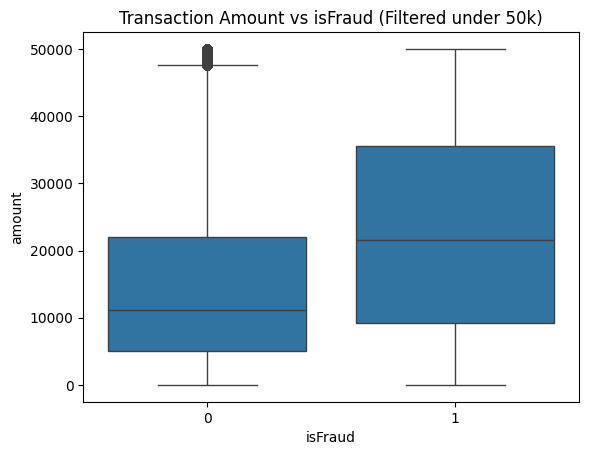

In [ ]:
#relationship between the fraud and the amount
filtered_df=df[df["amount"]<50000]

# use a box plot to see both classes Vs transfered amount
sns.boxplot(data=filtered_df,x="isFraud",y="amount")
plt.title("Transaction Amount vs isFraud (Filtered under 50k)")
plt.show()

In [ ]:
# create balance differnce features
df["balanceDiffOrig"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["balanceDiffDest"] = df["newbalanceDest"] - df["oldbalanceDest"]


In [ ]:
print((df["balanceDiffOrig"]<0).sum())

1399253


In [ ]:
print((df["balanceDiffDest"]<0).sum())

1238864


# Analyse the step feature

In [ ]:
# make a 24 hour cycle using step
df["hour_of_day"]=df['step']%24


In [ ]:
# calculate the average fraud rate per hour
fraud_rate= df.groupby("hour_of_day")['isFraud'].mean()*100


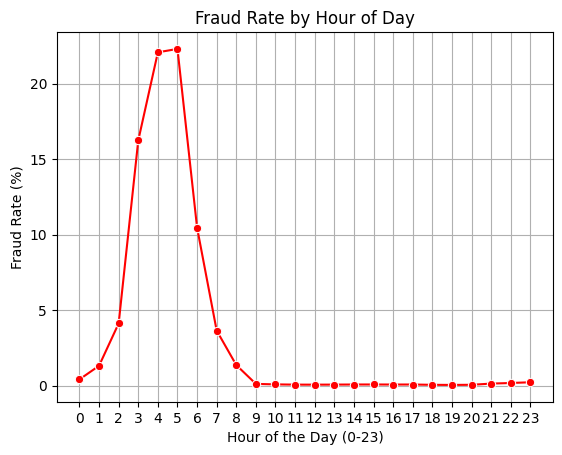

In [ ]:
# plot the real danger zones
sns.lineplot(x=fraud_rate.index, y=fraud_rate.values, marker="o", color="red")
plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of the Day (0-23)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

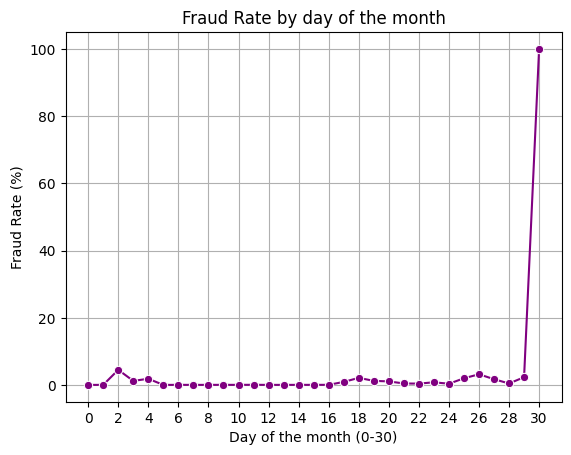

In [ ]:
# extract the day (0-30)
df['day_of_month']=df['step']//24

# calculate the average fraud rate per day
fraud_rate_per_day= df.groupby("day_of_month")['isFraud'].mean()*100

# plot the real danger zones
sns.lineplot(x=fraud_rate_per_day.index, y=fraud_rate_per_day.values, marker="o", color="purple")
plt.title("Fraud Rate by day of the month")
plt.xlabel("Day of the month (0-30)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 32,2))
plt.grid(True)
plt.show()


In [ ]:
# Filter out the glitchy final day (keeping days 0 through 29)
df = df[df['day_of_month'] < 30]

# Verify the maximum day is now 29
print(df['day_of_month'].max())

29


In [ ]:
# drop the step feature
df=df.drop(columns='step')

In [ ]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,amount_log,balanceDiffOrig,balanceDiffDest,hour_of_day,day_of_month
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9.194276,9839.64,0.0,1,0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,7.531166,1864.28,0.0,1,0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,5.204007,181.00,0.0,1,0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,5.204007,181.00,-21182.0,1,0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,9.364703,11668.14,0.0,1,0


# Analyse the custemor and recerivers name feature

In [ ]:
top_senders=df['nameOrig'].value_counts()


In [ ]:
top_senders.head(10)

,count
nameOrig,
C1677795071,3
C1784010646,3
C1065307291,3
C2098525306,3
C1530544995,3
C2051359467,3
C363736674,3
C400299098,3
C545315117,3


In [ ]:
top_recivers=df['nameDest'].value_counts()


In [ ]:
top_recivers.head(10)

,count
nameDest,
C1286084959,113
C985934102,109
C665576141,105
C2083562754,102
C1590550415,101
C248609774,101
C451111351,99
C1789550256,99
C1360767589,98


In [ ]:
# find the fraud custermors
fraud_user=df[df['isFraud']==1]['nameOrig'].value_counts().head(10)


In [ ]:
fraud_user

,count
nameOrig,
C1199258183,1
C1305486145,1
C840083671,1
C1420196421,1
C2101527076,1
C137533655,1
C1118430673,1
C749981943,1
C1334405552,1


# Analise the transaction types

since only transfer and cash out has only fraud rates we are going to filter that out

In [ ]:
fraud_types = df[df["type"].isin(["TRANSFER","CASH_OUT"])]


In [ ]:
fraud_types["type"].value_counts()

,count
type,
CASH_OUT,2237359
TRANSFER,532768


<Axes: xlabel='type', ylabel='count'>

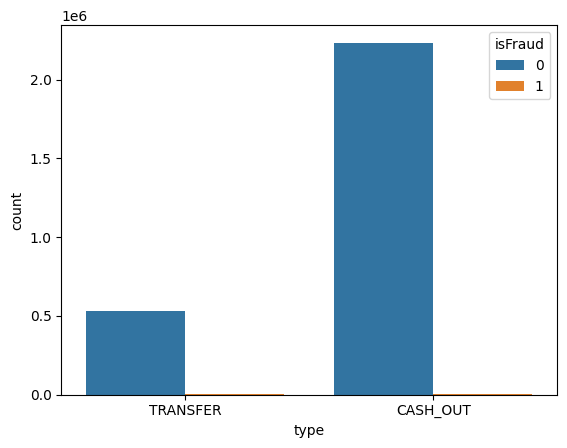

In [ ]:
sns.countplot(data=fraud_types, x="type", hue="isFraud")

## You can't see the orange bars (isFraud = 1) because of extreme class imbalance combined with a linear y-axis scale.


*  The Scale Mismatch: Your y-axis goes all the way up to 2.5 million to accommodate the massive volume of normal transactions.


*  The Tiny Numbers: Across the entire dataset, there are only a few thousand total fraud cases hidden among millions of safe ones. When a bar representing a few thousand items is plotted on a chart scaled to 2,500,000, its physical height on your screen is literally a fraction of a pixel. It is completely crushed visually.


**If you want the chart to reveal the fraud counts side-by-side, you can change the y-axis to a logarithmic scale, which stretches out small numbers so rare classes become visible:**


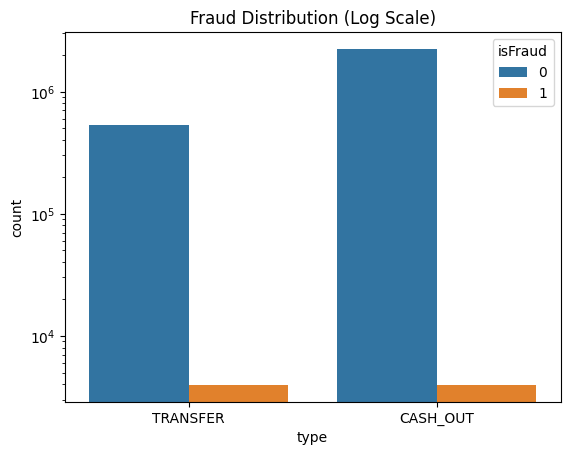

In [ ]:
sns.countplot(data=fraud_types, x="type", hue="isFraud")
plt.yscale("log")  # Stretches the scale for rare items
plt.title("Fraud Distribution (Log Scale)")
plt.show()

# build the correlation matrix
correlation can take -1 to +1

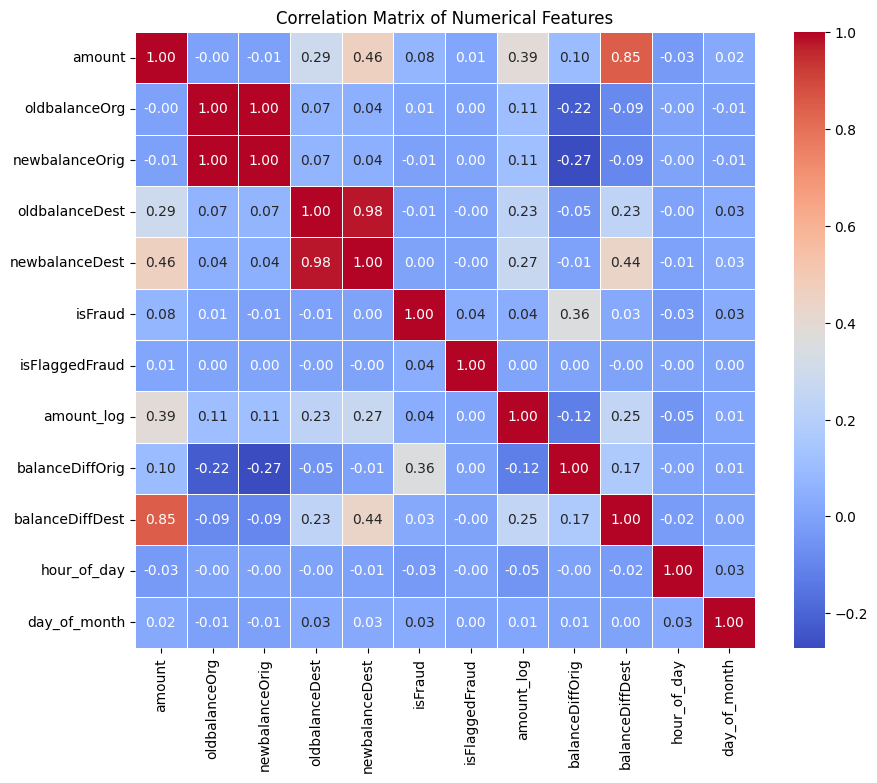

In [ ]:
# 1. Select only numerical columns (including our target and engineered features)
numerical_df=df.select_dtypes(include=['number'])

# 2. Calculate the Pearson correlation matrix
corr_matrix=numerical_df.corr()

#plot the correlation matrix using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

# Isolating Account-Draining Transactions
The Logic: This filter searches for transactions where an account started with a positive balance (oldbalanceOrg > 0), but after the transaction happened, its balance dropped completely to zero (newbalanceOrig == 0), specifically during a TRANSFER or CASH_OUT.

In [ ]:
zero_after_transfer = df[
    (df["oldbalanceOrg"] > 0) &
    (df["newbalanceOrig"] == 0) &
    (df["type"].isin(["TRANSFER", "CASH_OUT"]))
]

In [ ]:
len(zero_after_transfer)

1187808

In [ ]:
# Extract the first character of the destination name
dest_type = df['nameDest'].astype(str).str[0]
print(pd.crosstab(dest_type, df['isFraud'], normalize='index') * 100)

isFraud            0         1
nameDest                      
C          99.811653  0.188347
M         100.000000  0.000000


In [ ]:
# Check if the origin balance error matches the transaction amount for fraud cases
error_orig = (df['oldbalanceOrg'] - df['amount']) != df['newbalanceOrig']
print(pd.crosstab(error_orig, df['isFraud']))

isFraud        0     1
row_0                 
False     940537  7811
True     5413870   120


In [ ]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,amount_log,balanceDiffOrig,balanceDiffDest,hour_of_day,day_of_month
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9.194276,9839.64,0.0,1,0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,7.531166,1864.28,0.0,1,0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,5.204007,181.00,0.0,1,0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,5.204007,181.00,-21182.0,1,0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,9.364703,11668.14,0.0,1,0


# **Feature Engineering**

In [ ]:
df=df.drop(['isFlaggedFraud'],axis=1)
#axis=1 (or axis='columns'): Tells Pandas to look for the label
#"isFlaggedFraud" among the columns. It drops that entire vertical column from your dataset.

In [ ]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,amount_log,balanceDiffOrig,balanceDiffDest,hour_of_day,day_of_month
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,9.194276,9839.64,0.0,1,0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,7.531166,1864.28,0.0,1,0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,5.204007,181.00,0.0,1,0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,5.204007,181.00,-21182.0,1,0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,9.364703,11668.14,0.0,1,0


## STEP 1- splitting the data into train,test and validation we use Stratified Sampling.


In [ ]:
#Separate Features (X) and Target (y)

X= df.drop(columns=['isFraud'])  # drop isFraud
Y=df['isFraud']


In [ ]:
X.head(10)


,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,amount_log,balanceDiffOrig,balanceDiffDest,hour_of_day,day_of_month
0,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,9.194276,9839.64,0.00,1,0
1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,7.531166,1864.28,0.00,1,0
2,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,5.204007,181.00,0.00,1,0
3,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,5.204007,181.00,-21182.00,1,0
4,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,9.364703,11668.14,0.00,1,0
5,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,8.964275,7817.71,0.00,1,0
6,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,8.869085,7107.77,0.00,1,0
7,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,8.969878,7861.64,0.00,1,0
8,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,8.300370,2671.00,0.00,1,0
9,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,8.582751,5337.77,-1549.21,1,0


In [ ]:
Y.head(10)

,isFraud
0,0
1,0
2,1
3,1
4,0
5,0
6,0
7,0
8,0
9,0


# Step 2: Split Off the Test Set First

In [ ]:
from sklearn.model_selection import train_test_split
#carve out 15% for the final test set

X_train_val,X_test,Y_train_val,Y_test = train_test_split(
    X,Y,test_size=0.15,random_state=42,stratify=Y
)



# Step 3: Split the Remaining Data into Training and Validation Sets

In [ ]:
# Split remaining data into Training (~70% total) and Validation (~15% total)

X_train,X_val,Y_train,Y_val = train_test_split(
    X_train_val,Y_train_val,test_size=0.1765,random_state=42,stratify=Y_train_val
)


In [ ]:
print(f"Training set:   {X_train.shape[0]} rows")
print(f"Validation set: {X_val.shape[0]} rows")
print(f"Test set:       {X_test.shape[0]} rows")

Training set:   4453477 rows
Validation set: 954510 rows
Test set:       954351 rows


# Step 4: Extract Features & Drop Raw Columns Without Leakage

Now that your data is cleanly separated, you can safely extract your frequency counts and merchant flags using only X_train, and then drop the raw text columns from all three sets:

this prevents data leakage

In [ ]:
# 1. Calculate frequency dictionaries exclusively from X_train
sender_counts=X_train['nameOrig'].value_counts()
receiver_counts=X_train['nameDest'].value_counts()

for dataset in [X_train,X_val,X_test]:
  dataset['sender_freqency'] =dataset['nameOrig'].map(sender_counts).fillna(0)
  dataset['receiver_freqency'] =dataset['nameDest'].map(receiver_counts).fillna(0)

# merchant destination rule we discused early
# tells the ML model whether the destination account is a merchant account.
#M... destination → 1 → Merchant
#C... destination → 0 → Not a merchant
  dataset['is_merchant_dest']=dataset['nameDest'].astype(str).str.startswith('M').astype(int)




Drop the raw text columns

In [ ]:
columns_to_drop=['nameOrig','nameDest']
X_train=X_train.drop(columns=columns_to_drop)
X_val=X_val.drop(columns=columns_to_drop)
X_test=X_test.drop(columns=columns_to_drop)

In [ ]:
X_train.head()

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,amount_log,balanceDiffOrig,balanceDiffDest,hour_of_day,day_of_month,sender_freqency,receiver_freqency,is_merchant_dest
175615,PAYMENT,996.83,157.00,0.00,0.00,0.00,6.905583,157.00,0.00,12,0,1,1,1
4128181,CASH_OUT,395338.32,0.00,0.00,4414560.61,4809898.93,12.887500,0.00,395338.32,14,12,1,22,0
3409286,PAYMENT,1041.70,0.00,0.00,0.00,0.00,6.949569,0.00,0.00,15,10,1,1,1
5777559,CASH_OUT,313009.37,22288.00,0.00,0.00,313009.37,12.653992,22288.00,313009.37,16,16,1,3,0
3529046,CASH_IN,277152.35,21876983.28,22154135.62,729592.19,477392.22,12.532326,-277152.34,-252199.97,19,10,1,6,0


# One-Hot Encode
Because your transaction type has a few distinct categories, you need to turn them into binary columns (0s and 1s) using One-Hot Encoding.

In [ ]:
# One-hot encode the 'type' column for all sets
X_train = pd.get_dummies(X_train, columns=['type'], drop_first=True)
X_val = pd.get_dummies(X_val, columns=['type'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['type'], drop_first=True)

# Ensure all datasets have the exact same columns after one-hot encoding
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)



In [ ]:
numeric_features = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "amount_log",
    "balanceDiffOrig",
    "balanceDiffDest",
    "hour_of_day",
    "day_of_month",
    "sender_freqency",
    "receiver_freqency",
    "is_merchant_dest"
]

# Train using XGBoost

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix


# calculate the spw parameter
It gives the minority fraud class more importance during training.

In [ ]:
negetive_cases=(Y_train==0).sum()
positive_cases=(Y_train==1).sum()
spw= negetive_cases / positive_cases
print(f"Scale Pos Weight(spw):{spw:.2f}")

Scale Pos Weight(spw):801.28


# Initialize the XGBoost Classifier
Set up the model parameters. Using tree_method='hist' is absolutely critical here to prevent the Colab RAM crashes you experienced earlier, as it optimizes memory usage for massive datasets.

### initialize the model with Early Stopping parameters


Instead of guessing how many decision trees the model should build (e.g., exactly 100), you give the model a massive maximum limit (like 1,000) and tell it to check its accuracy against the validation set after every single tree. If the validation accuracy stops improving for a set number of rounds, the model automatically halts training. This prevents overfitting and captures the model at its absolute peak performance.

In [ ]:
xgb_model = xgb.XGBClassifier(
    n_estimators=1000,         # High limit; early stopping will cut this shor
    learning_rate=0.1,         # Step size shrinkage to prevent overfitting
    max_depth=5,               # How deep each tree can go
    scale_pos_weight=spw,      # Applies the penalty ratio for missing fraud cases
    tree_method='hist',        # Memory-efficient algorithm for 6.3M+ rows
    early_stopping_rounds=10     # Stop if validation score doesn't improve for 10 trees
)

# Train the Model
Pass the validation set into the .fit() method:
Use the eval_set parameter to feed X_val and Y_val into the training process so the model can score itself in real-time.





In [ ]:
print("Training the XGBoost model with Early Stopping...")

# Train the model and evaluate it against the validation set simultaneously
xgb_model.fit(
    X_train, Y_train,
    eval_set=[(X_val, Y_val)],   # The model checks this dataset to prevent overfitting
    verbose=50                   # Prints an update every 50 trees
)

print(f"Training stopped early at tree number: {xgb_model.best_iteration}")

Training the XGBoost model with Early Stopping...
[0]	validation_0-logloss:0.60517
[50]	validation_0-logloss:0.02799
[100]	validation_0-logloss:0.01659
[150]	validation_0-logloss:0.01210
[200]	validation_0-logloss:0.00927
[250]	validation_0-logloss:0.00740
[300]	validation_0-logloss:0.00625
[350]	validation_0-logloss:0.00537
[400]	validation_0-logloss:0.00465
[450]	validation_0-logloss:0.00413
[500]	validation_0-logloss:0.00374
[550]	validation_0-logloss:0.00334
[600]	validation_0-logloss:0.00308
[650]	validation_0-logloss:0.00281
[700]	validation_0-logloss:0.00260
[750]	validation_0-logloss:0.00244
[800]	validation_0-logloss:0.00228
[850]	validation_0-logloss:0.00216
[900]	validation_0-logloss:0.00203
[950]	validation_0-logloss:0.00192
[999]	validation_0-logloss:0.00183
Training stopped early at tree number: 999


In [ ]:
# from sklearn.metrics import classification_report, confusion_matrix

# print("Evaluating the baseline model on X_test...")

# # 1. Generate predictions on the unseen test set
# y_pred = xgb_model.predict(X_test)

# # 2. Print the Confusion Matrix
# print("\n--- Confusion Matrix ---")
# print(confusion_matrix(Y_test, y_pred))

# # 3. Print the Classification Report
# print("\n--- Classification Report ---")
# print(classification_report(Y_test, y_pred))

# Step-by-Step Hyperparameter Tuning

1. Define the Hyperparameter Grid
You define a "search space" of different values for the model's structure.

* max_depth: How deep the trees can grow (controls complexity).

* learning_rate: How aggressively the model updates its weights.

* subsample & colsample_bytree: Takes random fractions of data/columns to prevent overfitting.

2. Run the Randomized Search
This code will randomly test 10 different combinations from your grid. It uses a 3-fold cross-validation on your training data, but we pass your X_val and Y_val into the .fit() method so it continues to use Early Stopping to evaluate every single combination efficiently.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# 1. Take a 10% sample of your training data to tune safely
X_train_sample = X_train.sample(frac=0.1, random_state=42)
Y_train_sample = Y_train.loc[X_train_sample.index]

# 2. Define the search space
param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 9],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

# 3. Set up the base model for GPU ACCELERATION
xgb_base = xgb.XGBClassifier(
    n_estimators=500,
    scale_pos_weight=spw,
    tree_method='hist',
    device='cuda',             # CRITICAL: Forces XGBoost to use the T4 GPU
    random_state=42,
    early_stopping_rounds=10
)

# 4. Configure the Randomized Search
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=10,
    scoring='f1',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=1                   # CRITICAL: Keep at 1 to prevent CUDA out-of-memory errors
)

print("Starting GPU-Accelerated Hyperparameter Tuning on 10% Sample...")

# 5. Fit the search on the smaller sample
random_search.fit(
    X_train_sample,
    Y_train_sample,
    eval_set=[(X_val, Y_val)],
    verbose=False
)

print("\nBest Parameters found:")
print(random_search.best_params_)

Starting GPU-Accelerated Hyperparameter Tuning on 10% Sample...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [07:16:41] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, subsample=0.7; total time=   5.9s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, subsample=0.7; total time=   2.9s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, subsample=0.7; total time=   2.5s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=5, subsample=0.9; total time=   4.3s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=5, subsample=0.9; total time=   3.0s
[CV] END colsample_bytree=0.7, learning_rate=0.01, max_depth=5, subsample=0.9; total time=   3.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=9, subsample=1.0; total time=   3.7s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=9, subsample=1.0; total time=   4.6s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=9, subsample=1.0; total time=   3.6s
[CV] END colsample_bytree=1.0, learning_rate=0.01, max_depth=9, subsample=0.9; total time=   3.7s
[CV] END colsample_bytr

In [ ]:
# #clean memory before doing hyperparameter tuning
# import gc

# # 1. Delete the baseline model and prediction arrays
# try:
#     del xgb_model
#     del y_pred
# except NameError:
#     pass

# # 2. Delete heavy dataframes and variables from your earlier EDA steps
# try:
#     del df
#     del fraud_types, numerical_df, corr_matrix, zero_after_transfer, filtered_df
#     del top_senders, top_recivers, fraud_user, dest_type, error_orig
#     del sender_counts, receiver_counts
# except NameError:
#     pass

# # 3. Force Python to release the unreferenced memory back to Colab
# cleared_memory = gc.collect()

# print(f"Memory cleared! Garbage collector freed {cleared_memory} objects.")
# print("Your RAM is now optimized. You are ready to run RandomizedSearchCV.")

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV

# 1. Extract the winning parameters from the Randomized Search
best_params = random_search.best_params_
print("Building final model with these optimized parameters:", best_params)

# 2. Initialize the final model using the best parameters + GPU settings
final_xgb_model = xgb.XGBClassifier(
    **best_params,               # Unpacks the winning learning_rate, max_depth, etc.
    n_estimators=1000,           # High limit for early stopping
    scale_pos_weight=spw,        # Class imbalance penalty
    tree_method='hist',
    device='cuda',               # GPU acceleration
    random_state=42,
    early_stopping_rounds=10
)

print("\nTraining final model on the FULL 100% training dataset...")

# 3. Train on the full X_train dataset
final_xgb_model.fit(
    X_train,
    Y_train,
    eval_set=[(X_val, Y_val)],
    verbose=50                   # Print progress every 50 trees
)

print("\nEvaluating the TUNED model on X_test...")

# 4. Generate predictions on the unseen test set using the final model
y_pred_tuned = final_xgb_model.predict(X_test)

# 5. Print the results
print("\n--- Final Confusion Matrix ---")
print(confusion_matrix(Y_test, y_pred_tuned))

print("\n--- Final Classification Report ---")
print(classification_report(Y_test, y_pred_tuned))

Building final model with these optimized parameters: {'subsample': 0.9, 'max_depth': 9, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

Training final model on the FULL 100% training dataset...
[0]	validation_0-logloss:0.64532
[50]	validation_0-logloss:0.05365
[100]	validation_0-logloss:0.01341
[150]	validation_0-logloss:0.00793
[200]	validation_0-logloss:0.00578
[250]	validation_0-logloss:0.00412
[300]	validation_0-logloss:0.00303
[350]	validation_0-logloss:0.00237
[400]	validation_0-logloss:0.00198
[450]	validation_0-logloss:0.00168
[500]	validation_0-logloss:0.00145
[550]	validation_0-logloss:0.00129
[600]	validation_0-logloss:0.00118
[650]	validation_0-logloss:0.00109
[700]	validation_0-logloss:0.00103
[750]	validation_0-logloss:0.00098
[800]	validation_0-logloss:0.00095
[850]	validation_0-logloss:0.00093
[900]	validation_0-logloss:0.00092
[950]	validation_0-logloss:0.00090
[999]	validation_0-logloss:0.00090

Evaluating the TUNED model on X_test...

--- Final Confusion Matrix ---

# Purpose: These artifacts make the trained ML system portable so it can be integrated into the later Kafka + Docker + FastAPI real-time fraud detection pipeline.

In [ ]:
import joblib
from google.colab import files

# 1. Save the trained XGBoost model
model_filename = 'fraud_xgb_model.pkl'

joblib.dump(final_xgb_model, model_filename)

print(f"Model saved successfully as: {model_filename}")


# 2. Save the exact feature columns used by the model
feature_columns_filename = 'model_features.pkl'

joblib.dump(list(X_train.columns), feature_columns_filename)

print(f"Feature schema saved successfully as: {feature_columns_filename}")


# 3. Save frequency mappings used during feature engineering
frequency_maps = {
    'sender_counts': sender_counts.to_dict(),
    'receiver_counts': receiver_counts.to_dict()
}

frequency_maps_filename = 'frequency_maps.pkl'

joblib.dump(frequency_maps, frequency_maps_filename)

print(f"Frequency mappings saved successfully as: {frequency_maps_filename}")


# 4. Download all artifacts
# files.download(model_filename)  # Trained XGBoost model
# files.download(feature_columns_filename)  #Required feature names/order
files.download(frequency_maps_filename)  # Sender/receiver frequency mappings

Model saved successfully as: fraud_xgb_model.pkl
Feature schema saved successfully as: model_features.pkl
Frequency mappings saved successfully as: frequency_maps.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>